# Method 2: Simulated Annealing
We work on full grids: every number appears once and the given cells stay fixed.
The energy counts how far the lines are from M. When it reaches 0, we have a magic square.

In [59]:
import time
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## Problem
The magic constant, the 2N+2 lines, and a check for a finished square.

In [60]:
def magic_constant(n):
    return n * (n * n + 1) // 2


In [61]:
def get_lines(n):
    rows = [[i * n + j for j in range(n)] for i in range(n)]
    cols = [[i * n + j for i in range(n)] for j in range(n)]
    diag = [i * n + i for i in range(n)]
    anti = [i * n + (n - 1 - i) for i in range(n)]
    return rows + cols + [diag, anti]


In [62]:
def is_magic(square):
    square = np.array(square)
    n = len(square)
    flat = square.flatten()
    if sorted(flat.tolist()) != list(range(1, n * n + 1)):
        return False
    M = magic_constant(n)
    return all(flat[line].sum() == M for line in get_lines(n))


## Test puzzles
We take a known magic square, rotate or flip it, and keep a few cells as givens.

In [63]:
def siamese(n):
    sq = np.zeros((n, n), dtype=int)
    i, j = 0, n // 2
    for v in range(1, n * n + 1):
        sq[i, j] = v
        if sq[(i - 1) % n, (j + 1) % n] == 0:
            i, j = (i - 1) % n, (j + 1) % n
        else:
            i = (i + 1) % n
    return sq


In [64]:
def doubly_even(n):
    sq = np.arange(1, n * n + 1).reshape(n, n)
    for i in range(n):
        for j in range(n):
            if (i % 4 in (0, 3)) == (j % 4 in (0, 3)):
                sq[i, j] = n * n + 1 - sq[i, j]
    return sq


In [65]:
def singly_even(n):
    h = n // 2
    a = siamese(h)
    sq = np.block([[a, a + 2 * h * h], [a + 3 * h * h, a + h * h]])
    k = (n - 2) // 4
    for i in range(h):
        cols = list(range(k)) + list(range(n - k + 1, n))
        if i == h // 2:
            cols = [c + 1 if c < k else c for c in cols]
        for j in cols:
            sq[i, j], sq[i + h, j] = sq[i + h, j], sq[i, j]
    return sq


In [66]:
def make_puzzle(n, n_given=0, seed=None):
    rng = np.random.default_rng(seed)
    if n % 2 == 1:
        sol = siamese(n)
    elif n % 4 == 0:
        sol = doubly_even(n)
    else:
        sol = singly_even(n)
    #rotating or flipping keeps the square magic, so puzzles differ by seed
    sol = np.rot90(sol, rng.integers(4))
    if rng.random() < 0.5:
        sol = np.fliplr(sol)
    sol = np.array(sol)
    #keep n_given random cells of the solution, so the givens are consistent
    puzzle = np.zeros((n, n), dtype=int)
    cells = rng.choice(n * n, size=n_given, replace=False)
    puzzle.flat[cells] = sol.flat[cells]
    return puzzle


## Energy and moves
A move swaps two free cells. Only their lines change, so we only recompute those.

In [67]:
def random_state(puzzle, rng):
    grid = [int(x) for x in np.array(puzzle).flatten()]
    used = set(grid)
    #the free cells get the missing numbers in random order, so the grid
    #is always a permutation and all-different never breaks
    missing = [v for v in range(1, len(grid) + 1) if v not in used]
    rng.shuffle(missing)
    free = [c for c in range(len(grid)) if grid[c] == 0]
    for c, v in zip(free, missing):
        grid[c] = v
    return grid, free


In [68]:
def energy(sums, M):
    return sum(abs(s - M) for s in sums)


In [69]:
def swap_delta(grid, sums, a, b, lines_of, M):
    d = grid[b] - grid[a]
    change = {}
    for l in lines_of[a]:
        change[l] = change.get(l, 0) + d
    for l in lines_of[b]:
        change[l] = change.get(l, 0) - d
    de = 0
    for l, x in change.items():
        if x != 0:
            de += abs(sums[l] + x - M) - abs(sums[l] - M)
    return de, change


## Simulated annealing
Better moves are always taken. Worse ones are taken with probability exp(−Δ/T).
T starts high and slowly goes down. If a run gets stuck, we start again from a new grid.

In [70]:
def simulated_annealing(puzzle, iters_per_run=None, t_min=0.01,
                        time_limit=60, seed=None, trace=False):
    puzzle = np.array(puzzle)
    n = len(puzzle)
    M = magic_constant(n)
    lines = get_lines(n)
    lines_of = [[i for i, l in enumerate(lines) if c in l] for c in range(n * n)]
    rng = random.Random(seed)
    if iters_per_run is None:
        iters_per_run = 2000 * n * n

    start = time.time()
    total, restarts = 0, 0
    best_e, best_grid = None, None
    history = []

    while True:
        grid, free = random_state(puzzle, rng)
        sums = [sum(grid[c] for c in l) for l in lines]
        e = energy(sums, M)

        if len(free) >= 2:
            #starting temperature: average worsening of a random swap,
            #so at first a typical bad move is accepted about 1 time in 3
            worse = []
            for _ in range(200):
                a, b = rng.sample(free, 2)
                de, _ = swap_delta(grid, sums, a, b, lines_of, M)
                if de > 0:
                    worse.append(de)
            T = sum(worse) / len(worse) if worse else 1.0
            #geometric cooling that reaches t_min at the end of the run
            alpha = (t_min / T) ** (1 / iters_per_run)

            for _ in range(iters_per_run):
                if e == 0:
                    break
                if total % 1000 == 0 and time.time() - start > time_limit:
                    break
                a, b = rng.sample(free, 2)
                de, change = swap_delta(grid, sums, a, b, lines_of, M)
                #better moves always, worse ones with probability exp(-de/T)
                if de < 0 or rng.random() < math.exp(-de / T):
                    grid[a], grid[b] = grid[b], grid[a]
                    for l, x in change.items():
                        sums[l] += x
                    e += de
                T *= alpha
                total += 1
                if trace and total % 100 == 0:
                    history.append((total, e))
            if trace:
                history.append((total, e))

        if best_e is None or e < best_e:
            best_e, best_grid = e, grid[:]
        if e == 0 or len(free) < 2 or time.time() - start > time_limit:
            break
        #the run ended in a local minimum: restart from a new random grid
        restarts += 1

    square = np.array(best_grid).reshape(n, n)
    ok = best_e == 0 and is_magic(square)
    return {"status": "solved" if ok else "timeout", "square": square,
            "energy": best_e, "time": time.time() - start,
            "iterations": total, "restarts": restarts, "history": history}


## Experiment 2a
The same 4×4 puzzle as in Method 1. The plot shows the energy during the search.

In [71]:
puzzle = make_puzzle(4, n_given=3, seed=1)
print("M =", magic_constant(4))
print(puzzle)


M = 34
[[13  0 12  0]
 [ 0  0  0 15]
 [ 0  0  0  0]
 [ 0  0  0  0]]


In [72]:
r = simulated_annealing(puzzle, seed=0, trace=True)
print(f"{r['status']}, {r['time']:.3f} s, {r['iterations']} iterations, "
      f"{r['restarts']} restarts, final energy {r['energy']}")
print(r["square"])
print("magic:", is_magic(r["square"]),
      "| givens kept:", bool(np.all((puzzle == 0) | (puzzle == r["square"]))))


solved, 0.034 s, 6181 iterations, 0 restarts, final energy 0
[[13  3 12  6]
 [10  1  8 15]
 [ 7 16  9  2]
 [ 4 14  5 11]]
magic: True | givens kept: True


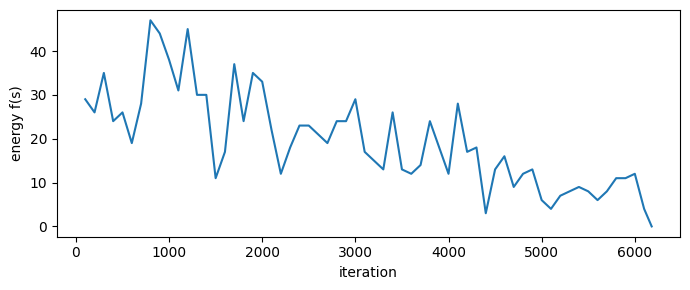

In [73]:
steps, values = zip(*r["history"])
plt.figure(figsize=(7, 3))
plt.plot(steps, values)
plt.xlabel("iteration")
plt.ylabel("energy f(s)")
plt.tight_layout()
plt.savefig("sa_energy.png", dpi=150)
plt.show()


## Experiment 2b
Sizes 3 to 10, with and without givens, 9 runs each, 10 seconds per run.
We go up to 10 because SA still solves squares that backtracking can't.

In [74]:
sizes = [3, 4, 5, 6, 7, 8, 9, 10]
given_fractions = [0.0, 0.2]
puzzle_seeds = range(3)
run_seeds = range(3)
time_limit = 10


In [75]:
rows = []
for n in sizes:
    for frac in given_fractions:
        for p in puzzle_seeds:
            puzzle = make_puzzle(n, n_given=int(frac * n * n), seed=p)
            for s in run_seeds:
                #the run seed is separate from the puzzle seed, so puzzle
                #difficulty and SA randomness are not mixed
                r = simulated_annealing(puzzle, time_limit=time_limit,
                                        seed=1000 + 10 * p + s)
                ok = r["status"] == "solved" and \
                     bool(np.all((puzzle == 0) | (puzzle == r["square"])))
                rows.append({"N": n, "givens": frac, "puzzle": p, "run": s,
                             "solved": ok, "time": r["time"],
                             "iterations": r["iterations"],
                             "restarts": r["restarts"]})
    print("N =", n, "done")


N = 3 done
N = 4 done
N = 5 done
N = 6 done
N = 7 done
N = 8 done
N = 9 done
N = 10 done


In [76]:
results = pd.DataFrame(rows)
results.to_csv("results_sa.csv", index=False)


## Results table

In [77]:
summary = results.groupby(["givens", "N"]).agg(
    solved=("solved", "mean"),
    median_time=("time", "median"),
    median_iterations=("iterations", "median"),
    median_restarts=("restarts", "median")).reset_index()
summary["solved"] = (100 * summary["solved"]).round().astype(int)
summary["median_time"] = summary["median_time"].round(3)
summary


,givens,N,solved,median_time,median_iterations,median_restarts
0,0.0,3,100,0.004,768.0,0.0
1,0.0,4,100,0.033,10236.0,0.0
2,0.0,5,100,1.364,377878.0,7.0
3,0.0,6,100,1.182,400790.0,5.0
4,0.0,7,100,1.053,358944.0,3.0
5,0.0,8,100,1.106,378250.0,2.0
6,0.0,9,78,1.705,594918.0,3.0
7,0.0,10,100,1.519,536508.0,2.0
8,0.2,3,100,0.002,359.0,0.0
9,0.2,4,100,0.024,7106.0,0.0


## Plot

In [78]:
results = pd.read_csv("results_sa.csv")
summary = results.groupby(["givens", "N"]).agg(
    solved=("solved", "mean"),
    median_time=("time", "median")).reset_index()
summary["solved"] = 100 * summary["solved"]


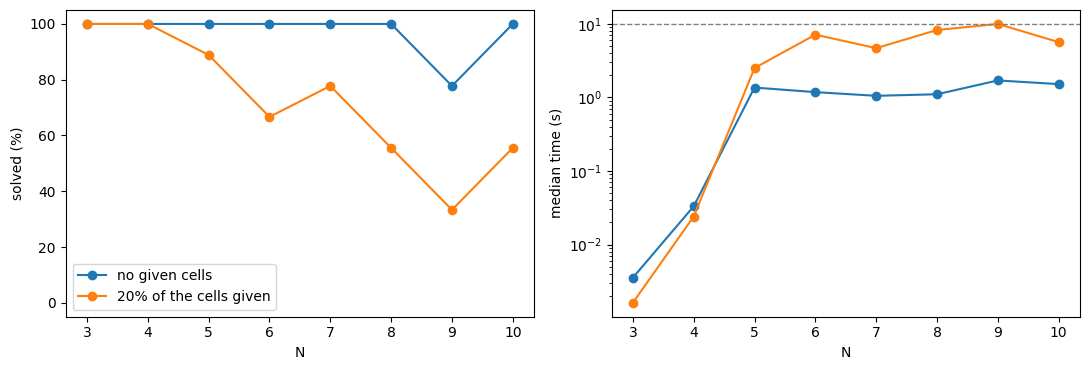

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for frac, g in summary.groupby("givens"):
    label = "no given cells" if frac == 0 else "20% of the cells given"
    axes[0].plot(g["N"], g["solved"], marker="o", label=label)
    axes[1].plot(g["N"], g["median_time"], marker="o", label=label)
axes[0].set_ylabel("solved (%)")
axes[0].set_ylim(-5, 105)
axes[1].axhline(time_limit, color="grey", linestyle="--", linewidth=1)
#log scale because times go from milliseconds to seconds
axes[1].set_yscale("log")
axes[1].set_ylabel("median time (s)")
for ax in axes:
    ax.set_xlabel("N")
    ax.set_xticks(sizes)
axes[0].legend()
plt.tight_layout()
plt.savefig("sa_time.png", dpi=150)
plt.show()
